In [1]:
import pandas as pd

# dataset
df = pd.read_csv("Instagram_Analytics.csv")

# Checking basic information
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

Shape: (29999, 23)

Columns:
['post_id', 'account_id', 'account_type', 'follower_count', 'media_type', 'content_category', 'traffic_source', 'has_call_to_action', 'post_datetime', 'post_date', 'post_hour', 'day_of_week', 'likes', 'comments', 'shares', 'saves', 'reach', 'impressions', 'engagement_rate', 'followers_gained', 'caption_length', 'hashtags_count', 'performance_bucket_label']

Missing values:
0

Duplicate rows:
0


In [2]:
#date columns into datetime format
df["post_datetime"] = pd.to_datetime(
    df["post_datetime"], errors="coerce"
)

df["post_date"] = pd.to_datetime(
    df["post_date"], errors="coerce"
)

print(df[["post_datetime", "post_date"]].dtypes)

print("\nInvalid post_datetime:", df["post_datetime"].isna().sum())
print("Invalid post_date:", df["post_date"].isna().sum())

post_datetime    datetime64[ns]
post_date        datetime64[ns]
dtype: object

Invalid post_datetime: 0
Invalid post_date: 0


In [3]:
numeric_cols = [
    "follower_count",
    "likes",
    "comments",
    "shares",
    "saves",
    "reach",
    "impressions",
    "engagement_rate",
    "followers_gained",
    "caption_length",
    "hashtags_count"
]

print(df[numeric_cols].describe().T)

                    count          mean          std     min       25%  \
follower_count    29999.0  10278.305477  6691.862669  3083.0  5824.000   
likes             29999.0    287.653588   317.647682     0.0   104.000   
comments          29999.0      8.521917    10.116505     0.0     3.000   
shares            29999.0     14.426614    16.420899     0.0     5.000   
saves             29999.0     42.517284    47.808844     0.0    15.000   
reach             29999.0   6272.475449  4985.877059   268.0  3058.000   
impressions       29999.0   8466.952498  6825.900355   327.0  4102.000   
engagement_rate   29999.0      0.042107     0.024095     0.0     0.024   
followers_gained  29999.0    502.152805   290.364038     0.0   251.000   
caption_length    29999.0    120.081169    11.009108    70.0   113.000   
hashtags_count    29999.0      7.987933     2.828130     0.0     6.000   

                        50%        75%         max  
follower_count    9044.0000  10739.000   31095.000  
likes

In [4]:
# Feature adding

df["share_rate"] = df["shares"] / df["reach"]

df["save_rate"] = df["saves"] / df["reach"]

df["comment_rate"] = df["comments"] / df["reach"]

df["like_rate"] = df["likes"] / df["reach"]

print(df[
    ["shares", "reach", "share_rate",
     "saves", "save_rate",
     "comments", "comment_rate",
     "likes", "like_rate"]
].head(10))

   shares  reach  share_rate  saves  save_rate  comments  comment_rate  likes  \
0       7   4327    0.001618     34   0.007858         5      0.001156    194   
1      21   7451    0.002818     68   0.009126        10      0.001342    449   
2       1   1639    0.000610     22   0.013423         2      0.001220    114   
3       7   2877    0.002433      0   0.000000         0      0.000000     91   
4       5   5350    0.000935     21   0.003925         8      0.001495    154   
5       4   2668    0.001499     23   0.008621         3      0.001124    149   
6      14   5018    0.002790     54   0.010761         9      0.001794    371   
7       0   1078    0.000000      3   0.002783         1      0.000928     18   
8       7   1900    0.003684     17   0.008947         4      0.002105    132   
9       3   2155    0.001392     12   0.005568         2      0.000928    101   

   like_rate  
0   0.044835  
1   0.060260  
2   0.069555  
3   0.031630  
4   0.028785  
5   0.055847  
6  

In [5]:
df["virality_score"] = (
    0.4 * df["share_rate"] +
    0.4 * df["save_rate"] +
    0.2 * df["comment_rate"]
)

print(df[
    ["post_id", "share_rate", "save_rate",
     "comment_rate", "virality_score"]
].head(10))

     post_id  share_rate  save_rate  comment_rate  virality_score
0  IG0000001    0.001618   0.007858      0.001156        0.004021
1  IG0000002    0.002818   0.009126      0.001342        0.005046
2  IG0000003    0.000610   0.013423      0.001220        0.005857
3  IG0000004    0.002433   0.000000      0.000000        0.000973
4  IG0000005    0.000935   0.003925      0.001495        0.002243
5  IG0000006    0.001499   0.008621      0.001124        0.004273
6  IG0000007    0.002790   0.010761      0.001794        0.005779
7  IG0000008    0.000000   0.002783      0.000928        0.001299
8  IG0000009    0.003684   0.008947      0.002105        0.005474
9  IG0000010    0.001392   0.005568      0.000928        0.002970


In [6]:
print(df["virality_score"].describe())

print("\nTop 10 posts by Virality Score:")
print(
    df[["post_id", "content_category", "media_type",
        "virality_score", "performance_bucket_label"]]
    .sort_values("virality_score", ascending=False)
    .head(10)
)

count    29999.000000
mean         0.003897
std          0.002291
min          0.000000
25%          0.002155
50%          0.003719
75%          0.005334
max          0.026955
Name: virality_score, dtype: float64

Top 10 posts by Virality Score:
         post_id content_category media_type  virality_score  \
7978   IG0007979             Food      image        0.026955   
27235  IG0027236             Food   carousel        0.025957   
18524  IG0018525          Fitness       reel        0.025010   
9153   IG0009154          Fashion       reel        0.024168   
17172  IG0017173      Photography   carousel        0.023885   
7500   IG0007501       Technology       reel        0.023885   
8247   IG0008248          Fashion   carousel        0.023361   
17614  IG0017615           Comedy       reel        0.023229   
13250  IG0013251          Fitness   carousel        0.022956   
11742  IG0011743       Technology   carousel        0.022953   

      performance_bucket_label  
7978            

In [7]:
print(df["performance_bucket_label"].value_counts())

print("\nPercentage distribution:")
print(
    df["performance_bucket_label"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

performance_bucket_label
viral     7500
high      7500
low       7500
medium    7499
Name: count, dtype: int64

Percentage distribution:
performance_bucket_label
viral     25.0
high      25.0
low       25.0
medium    25.0
Name: proportion, dtype: float64


In [8]:
features = [
    "follower_count",
    "media_type",
    "content_category",
    "traffic_source",
    "has_call_to_action",
    "post_hour",
    "day_of_week",
    "caption_length",
    "hashtags_count"
]

target = "performance_bucket_label"

X = df[features]
y = df[target]

print("Features:")
print(X.columns.tolist())

print("\nX shape:", X.shape)
print("y shape:", y.shape)

Features:
['follower_count', 'media_type', 'content_category', 'traffic_source', 'has_call_to_action', 'post_hour', 'day_of_week', 'caption_length', 'hashtags_count']

X shape: (29999, 9)
y shape: (29999,)


In [9]:
# for splitting data for training
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training data: (23999, 9)
Testing data: (6000, 9)

Training target distribution:
performance_bucket_label
viral     6000
low       6000
high      6000
medium    5999
Name: count, dtype: int64

Testing target distribution:
performance_bucket_label
low       1500
high      1500
medium    1500
viral     1500
Name: count, dtype: int64


In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Numerical features
numeric_features = [
    "follower_count",
    "post_hour",
    "caption_length",
    "hashtags_count"
]

# Categorical features
categorical_features = [
    "media_type",
    "content_category",
    "traffic_source",
    "has_call_to_action",
    "day_of_week"
]

# Create preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

print("Preprocessor created successfully!")

Preprocessor created successfully!


In [11]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Original X_train shape:", X_train.shape)
print("Processed X_train shape:", X_train_processed.shape)

print("Original X_test shape:", X_test.shape)
print("Processed X_test shape:", X_test_processed.shape)

Original X_train shape: (23999, 9)
Processed X_train shape: (23999, 32)
Original X_test shape: (6000, 9)
Processed X_test shape: (6000, 32)


In [12]:
from sklearn.ensemble import RandomForestClassifier

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model
rf_model.fit(X_train_processed, y_train)

print("Random Forest model trained successfully!")


Random Forest model trained successfully!


In [13]:
# Predict performance categories for test data
y_pred = rf_model.predict(X_test_processed)

print("Predictions generated successfully!")
print("\nFirst 10 predictions:")
print(y_pred[:10])

Predictions generated successfully!

First 10 predictions:
['high' 'low' 'high' 'low' 'high' 'low' 'high' 'high' 'medium' 'medium']


In [14]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

Model Accuracy: 23.88 %


In [15]:
from sklearn.metrics import confusion_matrix, classification_report

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Confusion Matrix:
[[380 387 366 367]
 [368 357 389 386]
 [384 393 335 388]
 [391 377 371 361]]

Classification Report:
              precision    recall  f1-score   support

        high       0.25      0.25      0.25      1500
         low       0.24      0.24      0.24      1500
      medium       0.23      0.22      0.23      1500
       viral       0.24      0.24      0.24      1500

    accuracy                           0.24      6000
   macro avg       0.24      0.24      0.24      6000
weighted avg       0.24      0.24      0.24      6000



In [16]:
print(
    df.groupby("performance_bucket_label")[
        ["follower_count", "post_hour", "caption_length", "hashtags_count"]
    ].mean().round(2)
)

                          follower_count  post_hour  caption_length  \
performance_bucket_label                                              
high                            10263.16      11.47          120.08   
low                             10279.16      11.60          120.14   
medium                          10288.63      11.51          120.10   
viral                           10282.28      11.42          120.00   

                          hashtags_count  
performance_bucket_label                  
high                                7.95  
low                                 7.98  
medium                              8.01  
viral                               8.01  


In [17]:
print(df["virality_score"].describe())

count    29999.000000
mean         0.003897
std          0.002291
min          0.000000
25%          0.002155
50%          0.003719
75%          0.005334
max          0.026955
Name: virality_score, dtype: float64


In [18]:
df["virality_level"] = pd.qcut(
    df["virality_score"],
    q=3,
    labels=["Low", "Medium", "High"]
)

print(df["virality_level"].value_counts())

virality_level
Low       10000
High      10000
Medium     9999
Name: count, dtype: int64


In [19]:
print(
    df.groupby("virality_level", observed=True)[
        ["follower_count", "post_hour", "caption_length", "hashtags_count"]
    ].mean().round(2)
)

                follower_count  post_hour  caption_length  hashtags_count
virality_level                                                           
Low                   10263.22      11.57          120.16            7.96
Medium                10340.07      11.49          119.92            8.02
High                  10231.63      11.44          120.16            7.98


In [20]:
cta_comparison = df.groupby("has_call_to_action")["engagement_rate"].agg(
    ["count", "mean"]
)

print(cta_comparison)

                    count      mean
has_call_to_action                 
0                   19536  0.042232
1                   10463  0.041875


In [21]:
media_comparison = df.groupby("media_type")["engagement_rate"].agg(
    ["count", "mean"]
).sort_values("mean", ascending=False)

print(media_comparison)

            count      mean
media_type                 
reel         7445  0.042266
image       11927  0.042256
carousel    10627  0.041829


In [22]:
from scipy.stats import f_oneway

reel = df[df["media_type"] == "reel"]["engagement_rate"]
image = df[df["media_type"] == "image"]["engagement_rate"]
carousel = df[df["media_type"] == "carousel"]["engagement_rate"]

f_stat, p_value = f_oneway(reel, image, carousel)

print("F-statistic:", f_stat)
print("P-value:", p_value)

# Media type does not show a statistically significant effect on engagement rate in this dataset.

F-statistic: 1.1016086529746159
P-value: 0.332349484960087


In [23]:
hour_comparison = df.groupby("post_hour")["engagement_rate"].agg(
    ["count", "mean"]
).sort_values("mean", ascending=False)

print(hour_comparison)

           count      mean
post_hour                 
3           1256  0.043425
8           1242  0.043282
2           1195  0.043279
17          1242  0.042693
20          1272  0.042684
14          1282  0.042640
4           1269  0.042377
5           1216  0.042355
16          1210  0.042245
9           1251  0.042196
21          1199  0.042152
12          1263  0.042066
18          1235  0.042046
0           1277  0.041930
13          1280  0.041898
11          1283  0.041882
1           1231  0.041882
6           1225  0.041605
22          1280  0.041549
19          1254  0.041523
23          1214  0.041367
10          1272  0.041301
15          1277  0.041271
7           1274  0.041018


In [24]:
from scipy.stats import f_oneway

hour_groups = [
    df[df["post_hour"] == hour]["engagement_rate"]
    for hour in sorted(df["post_hour"].unique())
]

f_stat, p_value = f_oneway(*hour_groups)

print("F-statistic:", f_stat)
print("P-value:", p_value)
#  Posting hour does not show a statistically significant effect on engagement rate in this dataset.

F-statistic: 0.9146740099877166
P-value: 0.5787980137247095


In [25]:
from scipy.stats import ttest_ind

cta = df[df["has_call_to_action"] == 1]["engagement_rate"]
no_cta = df[df["has_call_to_action"] == 0]["engagement_rate"]

t_stat, p_value = ttest_ind(cta, no_cta, equal_var=False)

print("T-statistic:", t_stat)
print("P-value:", p_value)
#  CTA does not show a statistically significant effect on engagement rate in this dataset

T-statistic: -1.2110999072794202
P-value: 0.2258707821764066


In [26]:
from scipy.stats import f_oneway

category_groups = [
    df[df["content_category"] == category]["engagement_rate"]
    for category in df["content_category"].unique()
]

f_stat, p_value = f_oneway(*category_groups)

print("Content Category ANOVA")
print("F-statistic:", f_stat)
print("P-value:", p_value)
# Content Category does not show a statistically significant effect on engagement rate in this dataset

Content Category ANOVA
F-statistic: 1.1703975347148672
P-value: 0.3090842652370214


In [27]:
traffic_groups = [
    df[df["traffic_source"] == source]["engagement_rate"]
    for source in df["traffic_source"].unique()
]

f_stat, p_value = f_oneway(*traffic_groups)

print("Traffic Source ANOVA")
print("F-statistic:", f_stat)
print("P-value:", p_value)
# Traffic Source does not show a statistically significant effect on engagement rate in this dataset

Traffic Source ANOVA
F-statistic: 1.4178978060787528
P-value: 0.21410455392554825


In [28]:
day_groups = [
    df[df["day_of_week"] == day]["engagement_rate"]
    for day in df["day_of_week"].unique()
]

f_stat, p_value = f_oneway(*day_groups)

print("Day of Week ANOVA")
print("F-statistic:", f_stat)
print("P-value:", p_value)
# Day of Week does not show a statistically significant effect on engagement rate in this dataset

Day of Week ANOVA
F-statistic: 1.2549579899796224
P-value: 0.2746538016106519


Although differences were observed across the tested factors, none were statistically significant (p > 0.05). Therefore, no tested factor can be considered a significant driver of engagement in this dataset.

In [29]:
import pandas as pd

comments_df = pd.read_csv("cleaned_instagram_comments.csv")

print("Original shape:", comments_df.shape)
print(comments_df.head())

Original shape: (14207, 2)
                                                text             username
0  instagram page private closed cannot viewed pu...              aqeede_
1  instagram page private closed cannot viewed pu...              aqeede_
2       underestimated stupidity voter believing lie     topdressurpferde
3  one threatens take away prosperity security jo...              aqeede_
4  one threatens take away prosperity security jo...  afshar_mohamadtaghi


In [30]:
# Step 1: Clean the Instagram comments dataset

# Remove rows where comment text is missing
comments_df = comments_df.dropna(subset=["text"])

# Remove duplicate comments
comments_df = comments_df.drop_duplicates()

# Reset index
comments_df = comments_df.reset_index(drop=True)

print("Cleaned dataset shape:", comments_df.shape)
print("Missing text:", comments_df["text"].isna().sum())
print("Duplicate rows:", comments_df.duplicated().sum())

Cleaned dataset shape: (9960, 2)
Missing text: 0
Duplicate rows: 0


In [31]:
print(comments_df["text"].sample(20, random_state=42).to_string(index=False))

                                             twice
                                  buddywitz legend
                                              cute
       black guy one big mistake america aka obama
                           admit administration ai
                             _nacirema interesting
          think forgot add good president sentence
                                        relateable
                                              love
                                                fr
mr trump wonderful strongest human determined t...
                           ill always choose obama
realdonaldtrump trust chummy new interloper please
donald trump im curious observe everything arou...
                           cody__randall obama yes
                                             twice
                                           f obama
           second inauguration thats even gangster
                                      pappy_james_
                             tr

In [32]:
!pip install -q vaderSentiment

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.0/126.0 kB 5.1 MB/s eta 0:00:00


In [33]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

analyzer = SentimentIntensityAnalyzer()

# Calculate sentiment score for every comment
comments_df["sentiment_score"] = comments_df["text"].apply(
    lambda x: analyzer.polarity_scores(str(x))["compound"]
)

# Convert score into sentiment label
def get_sentiment(score):
    if score >= 0.05:
        return "Positive"
    elif score <= -0.05:
        return "Negative"
    else:
        return "Neutral"

comments_df["sentiment"] = comments_df["sentiment_score"].apply(get_sentiment)

print(comments_df[["text", "sentiment_score", "sentiment"]].head(10))

                                                text  sentiment_score  \
0  instagram page private closed cannot viewed pu...           0.6022   
1       underestimated stupidity voter believing lie          -0.6124   
2  one threatens take away prosperity security jo...           0.9623   
3  one threatens take away prosperity security jo...           0.9623   
4                               way unc dropped main           0.0000   
5  elon musk considers moment first walked twitte...          -0.3182   
6                                        vrmtl whats           0.0000   
7                                         poor barry          -0.4767   
8  see someone said never break day inauguration ...           0.0000   
9  jabtak property ko seal nahi lagjata san usa j...           0.0000   

  sentiment  
0  Positive  
1  Negative  
2  Positive  
3  Positive  
4   Neutral  
5  Negative  
6   Neutral  
7  Negative  
8   Neutral  
9   Neutral  


In [34]:
print(comments_df["sentiment"].value_counts())

sentiment
Neutral     4602
Positive    3391
Negative    1967
Name: count, dtype: int64


In [35]:
sentiment_counts = comments_df["sentiment"].value_counts()

print(sentiment_counts)

print("\nPercentage distribution:")
print(
    comments_df["sentiment"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

sentiment
Neutral     4602
Positive    3391
Negative    1967
Name: count, dtype: int64

Percentage distribution:
sentiment
Neutral     46.20
Positive    34.05
Negative    19.75
Name: proportion, dtype: float64


In [36]:
relatable_patterns = [
    "same here",
    "me too",
    "i can relate",
    "i relate",
    "relatable",
    "literally me",
    "this is me",
    "this happened to me",
    "happened to me too",
    "happens to me",
    "i have experienced",
    "i experienced",
    "my experience",
    "going through this",
    "been through this",
    "i went through",
    "i've been through",
    "exactly me"
]

def detect_relatability(text):
    text = str(text).lower()

    for phrase in relatable_patterns:
        if phrase in text:
            return "Relatable"

    return "Neutral"

comments_df["relatability"] = comments_df["text"].apply(
    detect_relatability
)

print(comments_df[["text", "relatability"]].head(20))

                                                 text relatability
0   instagram page private closed cannot viewed pu...      Neutral
1        underestimated stupidity voter believing lie      Neutral
2   one threatens take away prosperity security jo...      Neutral
3   one threatens take away prosperity security jo...      Neutral
4                                way unc dropped main      Neutral
5   elon musk considers moment first walked twitte...      Neutral
6                                         vrmtl whats      Neutral
7                                          poor barry      Neutral
8   see someone said never break day inauguration ...      Neutral
9   jabtak property ko seal nahi lagjata san usa j...      Neutral
10  trump ive got faith youll make america great r...      Neutral
11  jbow call terrorism fight back terrorism corru...      Neutral
12  kirkland_cannon call terrorism fight back terr...      Neutral
13  president jabtakjail nahi jatehai protest band...      Neu

In [37]:
print(comments_df["relatability"].value_counts())

print("\nPercentage:")
print(
    comments_df["relatability"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

relatability
Neutral      9955
Relatable       5
Name: count, dtype: int64

Percentage:
relatability
Neutral      99.95
Relatable     0.05
Name: proportion, dtype: float64


In [38]:
print(comments_df["relatability"].value_counts())

relatability
Neutral      9955
Relatable       5
Name: count, dtype: int64


In [39]:
relatable_comments = comments_df[
    comments_df["relatability"] == "Relatable"
]

print("Relatable comments:", len(relatable_comments))

print(
    relatable_comments["text"]
    .head(50)
    .to_string(index=False)
)

Relatable comments: 5
                                    haha relatable
                                         relatable
                                         relatable
                                         relatable
thebrad exactly mentioned biggest obama lie lik...


In [40]:
comments_df.loc[
    comments_df["text"].str.contains(
        "exactly mentioned biggest obama lie",
        case=False,
        na=False
    ),
    "relatability"
] = "Neutral"

In [41]:
print(comments_df["relatability"].value_counts())

relatability
Neutral      9956
Relatable       4
Name: count, dtype: int64


Relatability Analysis: A rule-based linguistic approach was applied to identify explicit expressions of personal connection and shared experience, such as “same here,” “me too,” “I can relate,” and “literally me.” Among 9,960 cleaned comments, 4 comments (0.04%) were identified as explicitly relatable, while 9,956 (99.96%) were classified as neutral. This indicates that explicit expressions of personal relatability were rare in the available comment dataset.

In [42]:
def classify_resonance(row):
    sentiment = row["sentiment"]
    relatability = row["relatability"]

    if sentiment == "Positive" and relatability == "Relatable":
        return "Strong Positive Resonance"

    elif sentiment == "Negative" and relatability == "Relatable":
        return "Strong Negative Resonance"

    elif sentiment == "Neutral" and relatability == "Relatable":
        return "Relatable Neutral"

    else:
        return "Non-Relatable"


comments_df["emotional_resonance"] = comments_df.apply(
    classify_resonance,
    axis=1
)

print(comments_df["emotional_resonance"].value_counts())

emotional_resonance
Non-Relatable                9956
Relatable Neutral               3
Strong Positive Resonance       1
Name: count, dtype: int64


In [43]:
print("\nPercentage:")
print(
    comments_df["emotional_resonance"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)


Percentage:
emotional_resonance
Non-Relatable                99.96
Relatable Neutral             0.03
Strong Positive Resonance     0.01
Name: proportion, dtype: float64


In [44]:
resonance_comments = comments_df[
    comments_df["emotional_resonance"] != "Non-Relatable"
]

print(resonance_comments[
    ["text", "sentiment", "relatability", "emotional_resonance"]
].to_string(index=False))

          text sentiment relatability       emotional_resonance
haha relatable  Positive    Relatable Strong Positive Resonance
     relatable   Neutral    Relatable         Relatable Neutral
     relatable   Neutral    Relatable         Relatable Neutral
     relatable   Neutral    Relatable         Relatable Neutral


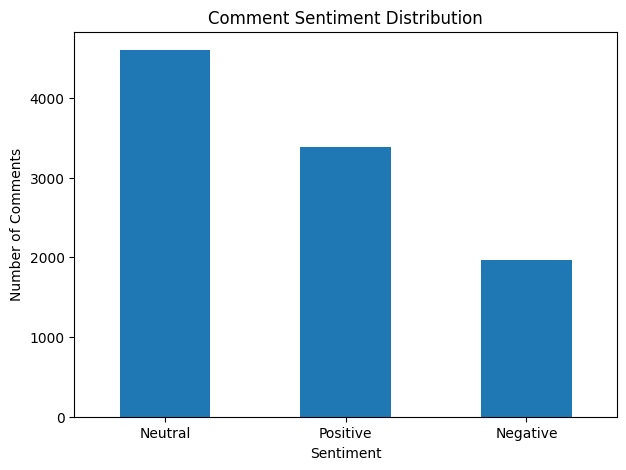

In [45]:
import matplotlib.pyplot as plt

sentiment_counts = comments_df["sentiment"].value_counts()

plt.figure(figsize=(7, 5))
sentiment_counts.plot(kind="bar")
plt.title("Comment Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Comments")
plt.xticks(rotation=0)
plt.show()


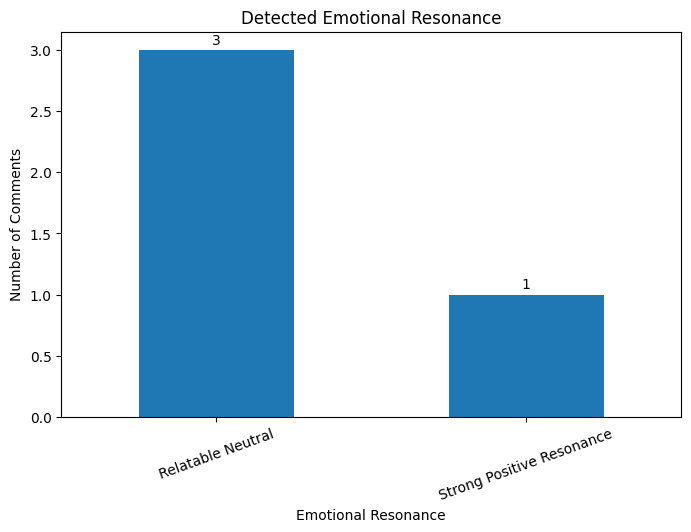

In [46]:
resonance_counts = comments_df[
    comments_df["emotional_resonance"] != "Non-Relatable"
]["emotional_resonance"].value_counts()

plt.figure(figsize=(8, 5))
ax = resonance_counts.plot(kind="bar")

plt.title("Detected Emotional Resonance")
plt.xlabel("Emotional Resonance")
plt.ylabel("Number of Comments")
plt.xticks(rotation=20)

for i, value in enumerate(resonance_counts):
    ax.text(i, value + 0.05, str(value), ha="center")

plt.show()

**Key Findings**
The sentiment analysis of 9,960 comments showed that 46.2% were Neutral, 34.1% Positive, and 19.7% Negative.
Neutral comments formed the largest category, indicating that many comments were informational, contextual, or did not express a strong emotional polarity.
Only 4 comments (0.04%) contained explicit linguistic patterns indicating personal relatability.
Among the detected relatable comments, 3 were Relatable Neutral and 1 showed Strong Positive Resonance.
No Strong Negative Resonance was detected in the rule-based analysis.
The low relatability detection should not be interpreted as proof that users did not relate to the content. It reflects the limitation of detecting relatability using predefined linguistic patterns.
These findings demonstrate that sentiment analysis can measure emotional tone, while relatability detection provides an additional signal of explicit personal connection.
Limitation

The relatability analysis used a rule-based approach based on predefined linguistic expressions. Therefore, implicit relatability, sarcasm, multilingual expressions, slang, and context-dependent comments may not have been detected.




**Conclusion**

The NLP module provides a structured approach to measuring audience sentiment and explicit emotional connection. These signals can be used alongside engagement metrics such as shares, saves, comments, and followers gained to better understand content that generates human connection.

In [47]:
category_performance = (
    df.groupby("content_category")
      .agg(
          avg_engagement=("engagement_rate", "mean"),
          total_shares=("shares", "sum"),
          total_saves=("saves", "sum"),
          total_posts=("post_id", "count")
      )
      .sort_values("avg_engagement", ascending=False)
)

category_performance["avg_engagement_pct"] = (
    category_performance["avg_engagement"] * 100
)

category_performance

,avg_engagement,total_shares,total_saves,total_posts,avg_engagement_pct
content_category,,,,,
Music,0.042808,43698,129215,3003,4.280759
Fitness,0.042720,43440,128029,3004,4.271961
Fashion,0.042615,44984,132092,3034,4.261519
Beauty,0.042197,43024,126363,2953,4.219739
Food,0.042078,43636,128571,3010,4.207767
Technology,0.042023,41813,124201,3025,4.202331
Comedy,0.041854,42805,127185,2950,4.185410
Travel,0.041677,41895,123242,2968,4.167692
Lifestyle,0.041646,43430,126388,3017,4.164604


In [48]:
media_performance = (
    df.groupby("media_type")
      .agg(
          avg_engagement=("engagement_rate", "mean"),
          total_shares=("shares", "sum"),
          total_saves=("saves", "sum"),
          total_posts=("post_id", "count")
      )
      .sort_values("avg_engagement", ascending=False)
)

media_performance["avg_engagement_pct"] = (
    media_performance["avg_engagement"] * 100
)

media_performance

,avg_engagement,total_shares,total_saves,total_posts,avg_engagement_pct
media_type,,,,,
reel,0.042266,106702,315328,7445,4.226641
image,0.042256,173762,509130,11927,4.225635
carousel,0.041829,152320,451018,10627,4.182856


In [49]:
import pandas as pd
import matplotlib.pyplot as plt

# monthly period
df["month"] = df["post_datetime"].dt.to_period("M").astype(str)

# average engagement for each category per month
monthly_trends = (
    df.groupby(["month", "content_category"])["engagement_rate"]
      .mean()
      .reset_index()
)

monthly_trends["engagement_pct"] = (
    monthly_trends["engagement_rate"] * 100
)

monthly_trends.head()

,month,content_category,engagement_rate,engagement_pct
0,2024-11,Beauty,0.039120,3.912018
1,2024-11,Comedy,0.043524,4.352447
2,2024-11,Fashion,0.039687,3.968710
3,2024-11,Fitness,0.044466,4.446600
4,2024-11,Food,0.040906,4.090642


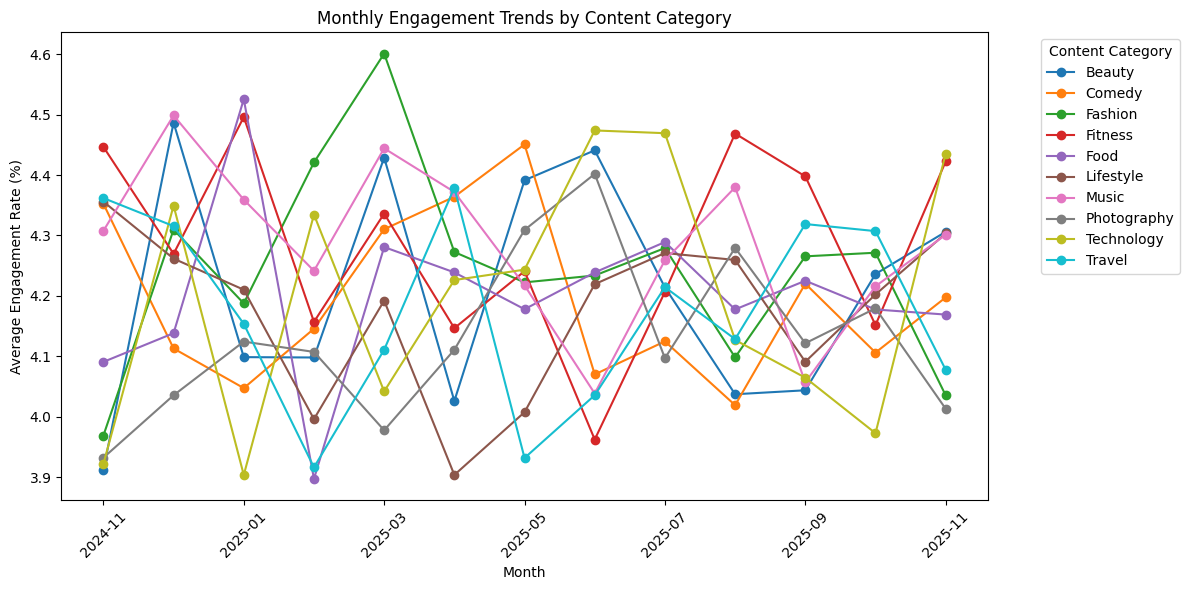

In [50]:
trend_pivot = monthly_trends.pivot(
    index="month",
    columns="content_category",
    values="engagement_pct"
)

trend_pivot.plot(figsize=(12, 6), marker="o")

plt.title("Monthly Engagement Trends by Content Category")
plt.xlabel("Month")
plt.ylabel("Average Engagement Rate (%)")
plt.xticks(rotation=45)
plt.legend(title="Content Category", bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

In [51]:
trend_change = (
    monthly_trends.sort_values("month")
    .groupby("content_category")
    .agg(
        first_month=("month", "first"),
        first_engagement=("engagement_pct", "first"),
        last_month=("month", "last"),
        last_engagement=("engagement_pct", "last")
    )
)

trend_change["change_percentage_points"] = (
    trend_change["last_engagement"]
    - trend_change["first_engagement"]
)

trend_change = trend_change.sort_values(
    "change_percentage_points",
    ascending=False
)

trend_change

,first_month,first_engagement,last_month,last_engagement,change_percentage_points
content_category,,,,,
Technology,2024-11,3.921698,2025-11,4.435515,0.513817
Beauty,2024-11,3.912018,2025-11,4.305962,0.393944
Photography,2024-11,3.932062,2025-11,4.013043,0.080982
Food,2024-11,4.090642,2025-11,4.168968,0.078326
Fashion,2024-11,3.968710,2025-11,4.035250,0.066540
Music,2024-11,4.307561,2025-11,4.301168,-0.006393
Fitness,2024-11,4.446600,2025-11,4.422485,-0.024115
Lifestyle,2024-11,4.355948,2025-11,4.303242,-0.052707
Comedy,2024-11,4.352447,2025-11,4.197361,-0.155086


In [52]:

monthly_trends["month_date"] = pd.to_datetime(
    monthly_trends["month"]
)

midpoint = monthly_trends["month_date"].median()

monthly_trends["period"] = monthly_trends["month_date"].apply(
    lambda x: "First half" if x <= midpoint else "Second half"
)

half_comparison = (
    monthly_trends.groupby(["content_category", "period"])
    ["engagement_pct"]
    .mean()
    .unstack()
)

half_comparison["change_pp"] = (
    half_comparison["Second half"] - half_comparison["First half"]
)

half_comparison.sort_values("change_pp", ascending=False)

period,First half,Second half,change_pp
content_category,,,
Technology,4.145738,4.257081,0.111342
Photography,4.085168,4.181964,0.096796
Lifestyle,4.132381,4.224342,0.091961
Food,4.192679,4.212768,0.020088
Travel,4.166903,4.180294,0.013390
Beauty,4.205902,4.212938,0.007035
Fitness,4.298905,4.268154,-0.030751
Fashion,4.283189,4.197148,-0.086041
Comedy,4.254719,4.122848,-0.131871
